In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
print('Libraries loaded.')

Libraries loaded.


In [2]:
train_csv = Path('../data/raw/FI2010_train.csv')
if not train_csv.exists():
    train_csv = Path('data/raw/FI2010_train.csv')

df = pd.read_csv(train_csv, skiprows=1, header=None)
df = df.iloc[:, 1:]  # drop index column
df.columns = range(df.shape[1])

X_raw = df.iloc[:, :40].to_numpy(dtype=np.float32)
y_raw = df.iloc[:, 144].to_numpy()
y = (y_raw - 1).astype(np.int64)

mu = X_raw.mean(axis=0)
sigma = X_raw.std(axis=0) + 1e-8
X_norm = (X_raw - mu) / sigma

print(f'Loaded: {train_csv}')
print(f'X shape: {X_raw.shape} | y shape: {y.shape}')
print(f'Label raw unique: {np.unique(y_raw).tolist()}')
print(f'Label mapped unique: {np.unique(y).tolist()}')
print(f'Normalized mean: {X_norm.mean():.4f} | std: {X_norm.std():.4f}')

Loaded: ..\data\raw\FI2010_train.csv
X shape: (362400, 40) | y shape: (362400,)
Label raw unique: [1.0, 2.0, 3.0]
Label mapped unique: [0, 1, 2]
Normalized mean: 0.0000 | std: 1.0000


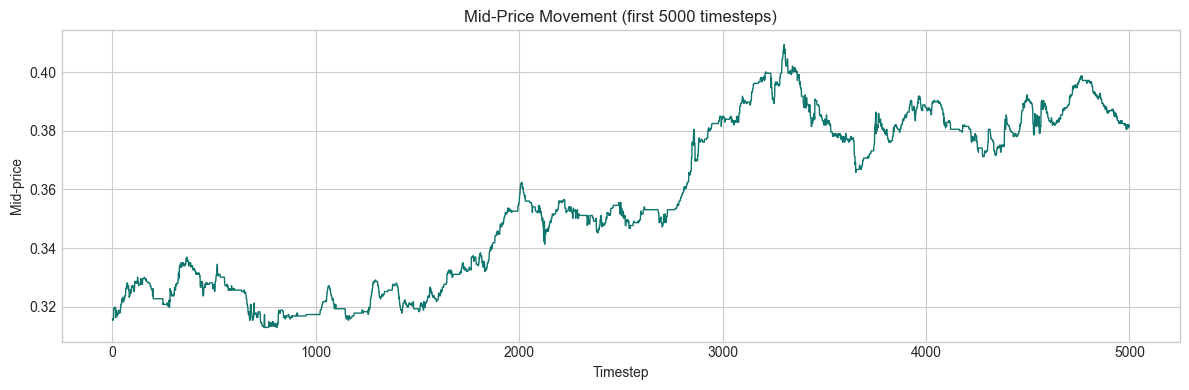

In [3]:
best_ask = X_raw[:, 0]
best_bid = X_raw[:, 2]
mid_price = (best_ask + best_bid) / 2.0

plot_n = min(5000, len(mid_price))
plt.figure(figsize=(12, 4))
plt.plot(mid_price[:plot_n], color='#0f766e', linewidth=1.0)
plt.title(f'Mid-Price Movement (first {plot_n} timesteps)')
plt.xlabel('Timestep')
plt.ylabel('Mid-price')
plt.tight_layout()
plt.show()

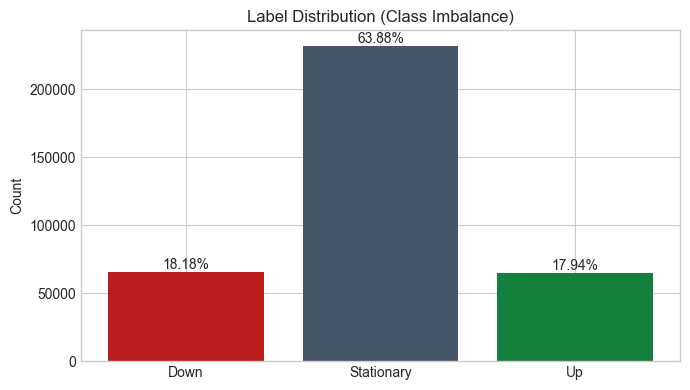

{'Down': 65882, 'Stationary': 231506, 'Up': 65012}


In [4]:
class_map = {0: 'Down', 1: 'Stationary', 2: 'Up'}
cls, counts = np.unique(y, return_counts=True)
labels = [class_map[int(c)] for c in cls]
fractions = counts / counts.sum()

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, counts, color=['#b91c1c', '#475569', '#15803d'])
plt.title('Label Distribution (Class Imbalance)')
plt.ylabel('Count')

for bar, frac in zip(bars, fractions):
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h, f'{frac*100:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()
print({class_map[int(c)]: int(n) for c, n in zip(cls, counts)})

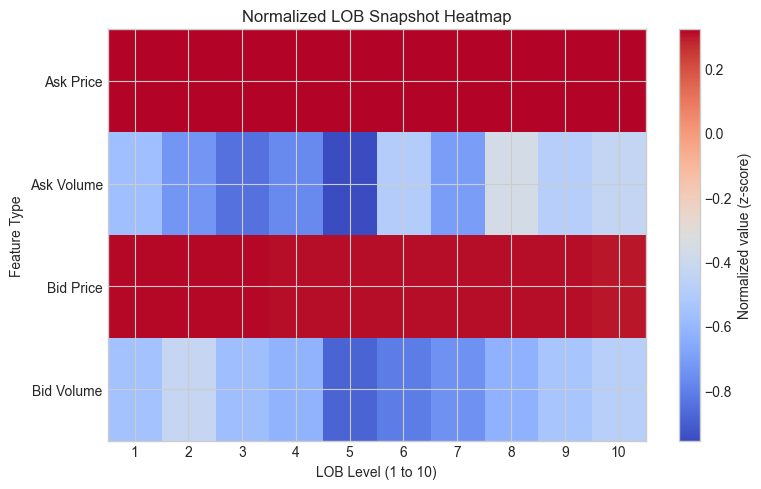

In [5]:
snapshot_idx = 0
snapshot = X_norm[snapshot_idx].reshape(10, 4)

plt.figure(figsize=(8, 5))
im = plt.imshow(snapshot.T, aspect='auto', cmap='coolwarm', interpolation='nearest')
plt.colorbar(im, label='Normalized value (z-score)')
plt.title('Normalized LOB Snapshot Heatmap')
plt.xlabel('LOB Level (1 to 10)')
plt.ylabel('Feature Type')
plt.yticks([0, 1, 2, 3], ['Ask Price', 'Ask Volume', 'Bid Price', 'Bid Volume'])
plt.xticks(ticks=range(10), labels=[str(i) for i in range(1, 11)])
plt.tight_layout()
plt.show()